In [18]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision 
from torchvision import datasets, transforms
# from torchvision import datasets,transforms
from torch.utils.data import DataLoader
# import torchvision.transforms as transforms


In [19]:
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


trainset=datasets.MNIST(root="./MSIST",train=True,download=True,transform=transform)
testset=datasets.MNIST(root="./MSIST",train=False,download=True,transform=transform)

In [20]:
trainloader=DataLoader(trainset,batch_size=32,shuffle=True)
testloader=DataLoader(testset,batch_size=32)

In [24]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN,self).__init__()

        self.conv_layer=nn.Sequential(
            nn.Conv2d(1,32,kernel_size=3,padding=1),  #convolutional layer
            nn.ReLU(),                           #Relu
            nn.MaxPool2d(2,2),                   #pooling

            nn.Conv2d(32,64,kernel_size=3,padding=1),  #convolutional layer
            nn.ReLU(),                            #Relu
            nn.MaxPool2d(2,2),                    #pooling

            nn.Conv2d(64,128,kernel_size=3,padding=1),  #convolutional layer
            nn.ReLU(),                             #Relu
            nn.MaxPool2d(2,2),                     #pooling
        )

        self.fc_layer=nn.Sequential(
            nn.Linear(3*3*128,256),
            nn.ReLU(),

            nn.Linear(256,10)
        )

    def forward(self,x):
        x=self.conv_layer(x)
        x=x.view(x.size(0),-1)  #flattening
        x=self.fc_layer(x)

        return x

In [25]:
model=CNN()

#loss and optimizer
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters())

In [27]:
train_losses=[]
val_losses=[]

best_val_loss=float("inf")


epochs=10

for epoch in range(epochs):
    model.train()

    
    running_loss=0.0

    for image,labels in trainloader:
        optimizer.zero_grad()

        output=model.forward(image)   #fP
        loss=criterion(output,labels) #loss fnx
        loss.backward()               #bp
        optimizer.step()              #update parent

        running_loss+=loss.item()
        
    epoch_train_loss=running_loss/len(trainloader)
    train_losses.append(epoch_train_loss)


     #validation
    model.eval()
    running_val_loss=0.0

    with torch.no_grad():  #no gradient compute
        for image,labels in testloader:
            outputs=model(image)
            loss=criterion(outputs,labels)
            running_val_loss += loss.item()


    epoch_val_loss=running_val_loss/len(testloader)
    val_losses.append(epoch_val_loss)

    

    print(f"epoch {epoch+1}/{epochs}==> train loss =${epoch_train_loss} & val loss= ${epoch_val_loss}")


    if epoch_val_loss<best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),"MNIST_0-9_best_model.pt") #.pt .pth to save file
    

epoch 1/10==> train loss =$0.07151577534281338 & val loss= $0.06563686798439645
epoch 2/10==> train loss =$0.03930934609118073 & val loss= $0.04419224385940916
epoch 3/10==> train loss =$0.027597893996793816 & val loss= $0.03134855604336384
epoch 4/10==> train loss =$0.021617558103732577 & val loss= $0.033986802585130094
epoch 5/10==> train loss =$0.017320816662507725 & val loss= $0.03426100127466132
epoch 6/10==> train loss =$0.01430926857845158 & val loss= $0.030281733907086623
epoch 7/10==> train loss =$0.012576304331380348 & val loss= $0.04194966232782193
epoch 8/10==> train loss =$0.011393440715749898 & val loss= $0.038779649615859106
epoch 9/10==> train loss =$0.009787055860233132 & val loss= $0.029075290906185183
epoch 10/10==> train loss =$0.009869971911615033 & val loss= $0.032664120349275516


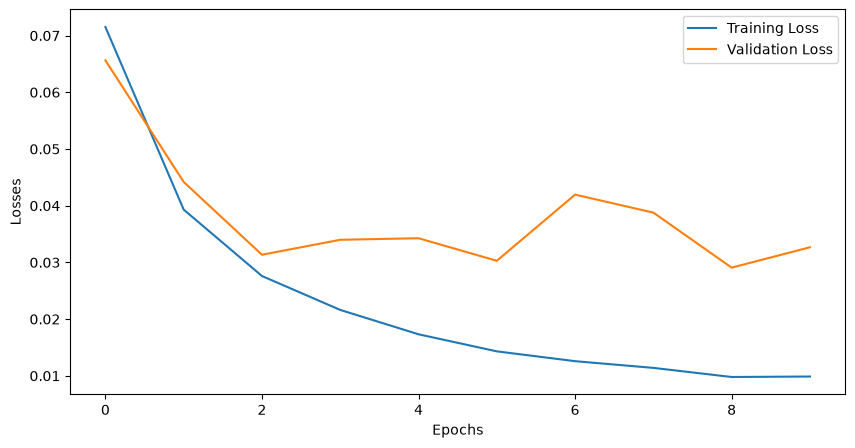

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

loss_df=pd.DataFrame({
   "Training Loss":train_losses,
   "Validation Loss":val_losses
})

plt.figure(figsize=(10,5))
plt.plot(loss_df["Training Loss"],label="Training Loss")
plt.plot(loss_df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [30]:
#lording the best model
model.load_state_dict(torch.load("MNIST_0-9_best_model.pt"))

<All keys matched successfully>

In [31]:
#Evalutate the CNN

correct_labels=0
total_labels=0

model.eval()

with torch.no_grad():
    for images,labels in testloader:
        output=model.forward(images)
        _,predicted=torch.max(output,1)

        correct_labels+=(predicted==labels).sum().item()
        total_labels+=labels.size(0)  #actual sample in each batch

print("total val",total_labels)
print("correct pred",correct_labels)

print("accuracy score",correct_labels/total_labels)
  

total val 10000
correct pred 9932
accuracy score 0.9932
